# Módulo 2: Modelado, Baseline y Evaluación
## Proyecto Final MLOps — Predicción de Precios de Vehículos de Ocasión (CarDekho)

### 1. Justificación Problema → Tarea → Métrica (M2.1)
* **Problema:** Estimar el precio de reventa justo de un coche de segunda mano a partir de sus características básicas (`brand`, `car_model`, `year`, `km_driven`, `fuel`, `seller_type`, `transmission`, `owner`).
* **Tarea:** Regresión supervisada sobre `selling_price`.
* **Métrica Principal — MAE (Mean Absolute Error):** Se elige frente al MSE porque se expresa directamente en unidades monetarias (rupias/euros) y no amplifica desproporcionadamente los errores de unos pocos coches de lujo. Un comprador o vendedor entiende al instante qué significa un MAE de ~118.000 INR (~1.308 €).
* **Métricas Complementarias:**
  - **RMSE (Root Mean Squared Error):** Para vigilar si hay desviaciones grandes en vehículos caros.
  - **R²:** Para medir qué porcentaje de la variabilidad del precio explica el modelo.

### 2. Estrategia de Split sin Fugas (M2.3)
* Partición fija (`random_state=42`): **Train (70% — 2.487 filas)**, **Validation (15% — 534 filas)** y **Test (15% — 534 filas)**.
* **Sin fuga de datos:** El `ColumnTransformer` (`StandardScaler` + `OneHotEncoder`) se ajusta **únicamente** sobre `Train` dentro de un `Pipeline` de `scikit-learn`.
* Todas las comparaciones de modelos se deciden sobre **Validation**. El conjunto **Test** permanece sellado hasta evaluar al modelo ganador.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
SEED = 42

train_df = pd.read_csv("../data/processed/train.csv")
val_df = pd.read_csv("../data/processed/val.csv")
test_df = pd.read_csv("../data/processed/test.csv")

features = ["year", "km_driven", "fuel", "seller_type", "transmission", "owner", "brand", "car_model"]
target = "selling_price"

X_train, y_train = train_df[features], train_df[target]
X_val, y_val = val_df[features], val_df[target]
X_test, y_test = test_df[features], test_df[target]

print(f"Particiones: Train={len(X_train)}, Val={len(X_val)}, Test={len(X_test)}")

Particiones: Train=2487, Val=534, Test=534


### 3. Baseline Dummy vs 3 Familias de Modelos (M2.2)
Comparamos un `DummyRegressor(strategy="mean")` (baseline de "no hacer nada") frente a **Ridge** (lineal), **Random Forest** (bagging) y **Gradient Boosting** (boosting), todos con `random_state=42`.

In [2]:
cat_cols = ["brand", "car_model", "fuel", "seller_type", "transmission", "owner"]
num_cols = ["year", "km_driven"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ]
)

models = {
    "Dummy (Media)": DummyRegressor(strategy="mean"),
    "Ridge Regressor": Pipeline([("prep", preprocessor), ("model", Ridge(alpha=1.0, random_state=SEED))]),
    "Random Forest": Pipeline([("prep", preprocessor), ("model", RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1))]),
    "Gradient Boosting": Pipeline([("prep", preprocessor), ("model", GradientBoostingRegressor(n_estimators=100, random_state=SEED))]),
}

records = []
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_val)
    records.append({
        "Modelo": name,
        "Val MAE": round(mean_absolute_error(y_val, preds), 0),
        "Val RMSE": round(root_mean_squared_error(y_val, preds), 0),
        "Val R²": round(r2_score(y_val, preds), 4),
    })

results_df = pd.DataFrame(records)
display(results_df)

dummy_mae = results_df.loc[0, "Val MAE"]
best_row = results_df.iloc[1:].sort_values("Val MAE").iloc[0]
mejora = (1 - best_row["Val MAE"] / dummy_mae) * 100
print(f"Ganador en Validación: {best_row['Modelo']} -> reduce el MAE del Dummy en un {mejora:.1f}%")

,Modelo,Val MAE,Val RMSE,Val R²
0,Dummy (Media),292053.0,471951.0,-0.0005
1,Ridge Regressor,121759.0,249660.0,0.7200
2,Random Forest,119437.0,289737.0,0.6229
3,Gradient Boosting,130081.0,234719.0,0.7525


Ganador en Validación: Random Forest -> reduce el MAE del Dummy en un 59.1%


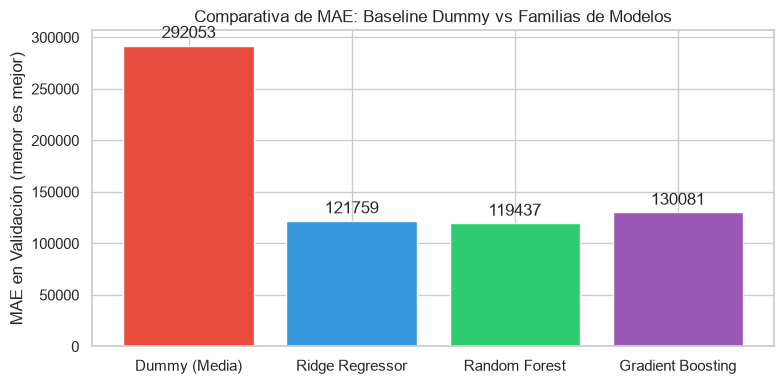

In [3]:
# Comparativa visual Dummy vs Modelos
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(results_df["Modelo"], results_df["Val MAE"], color=["#e74c3c", "#3498db", "#2ecc71", "#9b59b6"])
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.set_ylabel("MAE en Validación (menor es mejor)")
ax.set_title("Comparativa de MAE: Baseline Dummy vs Familias de Modelos")
plt.tight_layout()
plt.show()

### 4. Evaluación Final en Test Set (Sellado) y Resultados Visuales (M2.4)
Evaluamos el ganador (`Random Forest`) sobre el conjunto de Test y revisamos residuales, dispersión real vs predicho y distribución del error.

Test MAE:  117,717 INR (~1,308 EUR)
Test RMSE: 273,935 INR
Test R²:   0.7113


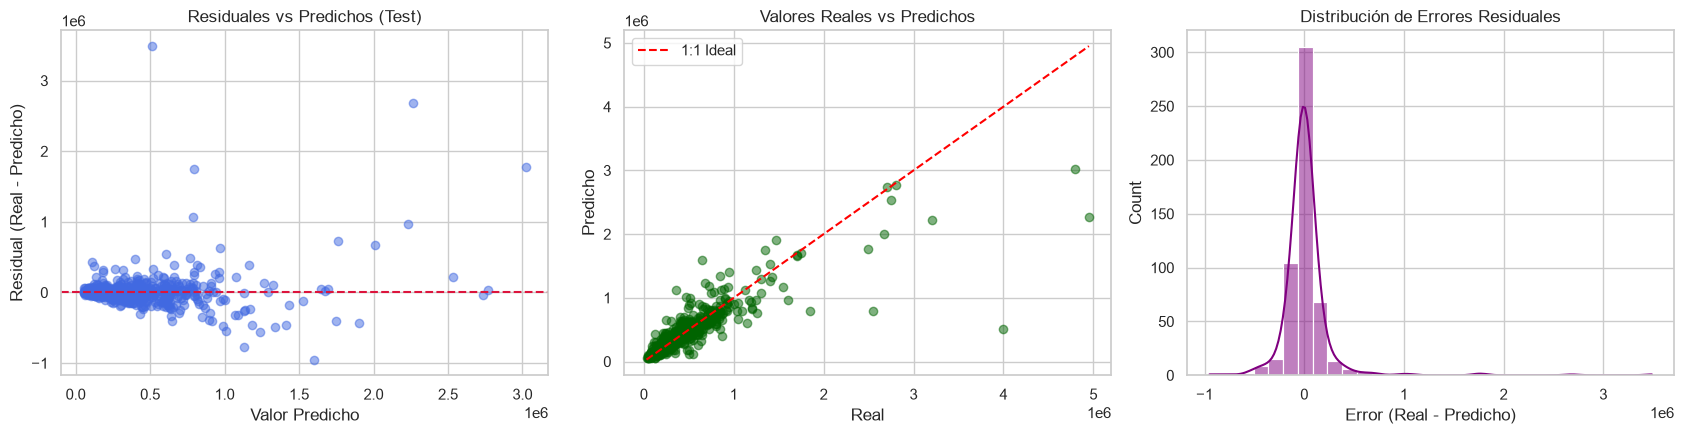

In [4]:
champion = models[best_row["Modelo"]]
test_preds = champion.predict(X_test)
residuals = y_test - test_preds

print(f"Test MAE:  {mean_absolute_error(y_test, test_preds):,.0f} INR (~{mean_absolute_error(y_test, test_preds)/90:,.0f} EUR)")
print(f"Test RMSE: {root_mean_squared_error(y_test, test_preds):,.0f} INR")
print(f"Test R²:   {r2_score(y_test, test_preds):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1. Residuales vs Predicción
axes[0].scatter(test_preds, residuals, alpha=0.5, color="royalblue")
axes[0].axhline(0, color="crimson", linestyle="--")
axes[0].set_title("Residuales vs Predichos (Test)")
axes[0].set_xlabel("Valor Predicho")
axes[0].set_ylabel("Residual (Real - Predicho)")

# 2. Reales vs Predichos
axes[1].scatter(y_test, test_preds, alpha=0.5, color="darkgreen")
diag = np.linspace(min(y_test.min(), test_preds.min()), max(y_test.max(), test_preds.max()), 100)
axes[1].plot(diag, diag, color="red", linestyle="--", label="1:1 Ideal")
axes[1].set_title("Valores Reales vs Predichos")
axes[1].set_xlabel("Real")
axes[1].set_ylabel("Predicho")
axes[1].legend()

# 3. Distribución de Residuales
sns.histplot(residuals, kde=True, ax=axes[2], color="purple", bins=30)
axes[2].set_title("Distribución de Errores Residuales")
axes[2].set_xlabel("Error (Real - Predicho)")

plt.tight_layout()
plt.show()